# Edge NSPPK Demo

This notebook shows how NSPPK builds edge-level representations and uses continuous edge attributes in graph features. Each edge receives the sum of the structural feature rows for its two endpoints. Continuous edge vectors then weight those edge rows, while optional clustering can inject edge-derived labels into the existing hash pipeline.

We use three small labeled graphs: a reference, a graph with changed edge attributes, and one with a structural edit.

In [1]:
from pathlib import Path
import sys

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(candidate for candidate in REPO_CANDIDATES if (candidate / 'src').exists())
SRC_DIR = REPO_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

from nsppk import EdgeNSPPK, NSPPK, get_structural_edge_vectors, get_structural_node_vectors

RADIUS = 1
DISTANCE = 2
NBITS = 6
FEATURE_WIDTH = 2**NBITS
print(f'Hashed structural width: {FEATURE_WIDTH}')

Hashed structural width: 64


## Make a controlled graph family

Node labels and topology are the same in the first two graphs, while their continuous edge attributes differ. The third graph changes one connection. Node and edge labels remain discrete so we can also exercise NSPPK's existing structural hashing path.

In [2]:
NODE_LABELS = ['C', 'N', 'C', 'O', 'S']
BASE_EDGE_ATTRIBUTES = [
    np.asarray([1.00, 0.20]),
    np.asarray([1.40, 0.80]),
    np.asarray([1.00, 0.30]),
    np.asarray([1.50, 0.60]),
]


def make_graph(attribute_variant='reference', topology_variant=False):
    graph = nx.Graph()
    graph.add_nodes_from(range(len(NODE_LABELS)))
    graph.add_edges_from([(0, 1), (1, 2), (2, 3), (3, 4)])
    if topology_variant:
        graph.remove_edge(1, 2)
        graph.add_edge(1, 3)

    node_features = [
        np.asarray([1.0, 0.0]),
        np.asarray([0.0, 1.0]),
        np.asarray([0.5, 0.5]),
        np.asarray([1.0, 1.0]),
        np.asarray([0.2, 0.8]),
    ]
    for node, label, feature in zip(graph.nodes(), NODE_LABELS, node_features):
        graph.nodes[node]['label'] = label
        graph.nodes[node]['node_feature'] = feature

    edge_attributes = [feature.copy() for feature in BASE_EDGE_ATTRIBUTES]
    if attribute_variant == 'shifted':
        edge_attributes[1][1], edge_attributes[2][1] = edge_attributes[2][1], edge_attributes[1][1]
    for edge_index, (u, v) in enumerate(graph.edges()):
        graph.edges[u, v]['label'] = 'double' if edge_index == 1 else 'single'
        graph.edges[u, v]['edge_feature'] = edge_attributes[edge_index]
    return graph


graphs = [
    make_graph(),
    make_graph(attribute_variant='shifted'),
    make_graph(topology_variant=True),
]
graph_names = ['reference', 'edge attributes shifted', 'topology changed']
[(name, graph.number_of_nodes(), graph.number_of_edges()) for name, graph in zip(graph_names, graphs)]

[('reference', 5, 4),
 ('edge attributes shifted', 5, 4),
 ('topology changed', 5, 4)]

## Inspect the edge attributes

The edge annotations show the second continuous channel (`strength`). The matrix rows used by `EdgeNSPPK` follow the exact order returned by `graph.edges()`.

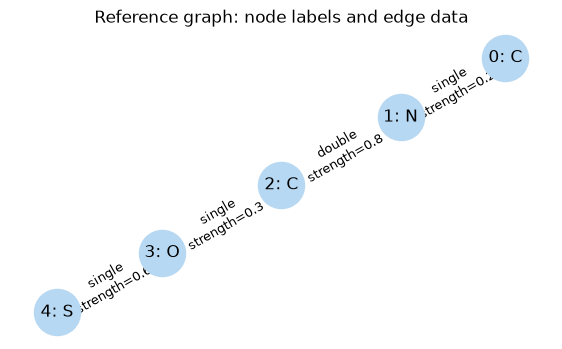

In [3]:
graph = graphs[0]
positions = nx.spring_layout(graph, seed=4)
node_labels = {node: f"{node}: {graph.nodes[node]['label']}" for node in graph.nodes()}
edge_labels = {
    (u, v): f"{graph.edges[u, v]['label']}\nstrength={graph.edges[u, v]['edge_feature'][1]:.1f}"
    for u, v in graph.edges()
}

fig, ax = plt.subplots(figsize=(7, 4))
nx.draw_networkx(graph, positions, labels=node_labels, node_color='#b7d8f2', node_size=1100, ax=ax)
nx.draw_networkx_edge_labels(graph, positions, edge_labels=edge_labels, font_size=9, ax=ax)
ax.set_title('Reference graph: node labels and edge data')
ax.axis('off')
plt.show()

## Build one feature row per edge

Without edge attributes, `EdgeNSPPK` returns the structural edge matrix. With attributes of width `P`, the output columns are `[raw edge attributes | attribute–structure interactions | structural edge features]`, for a total width of `D + 2P`.

The structural row for an edge is the sum of its two endpoint rows. This reuses the same NSPPK node features and hash caches that generate the node representation.

In [4]:
edge_encoder = EdgeNSPPK(
    radius=RADIUS,
    distance=DISTANCE,
    nbits=NBITS,
    dense=False,
    parallel=False,
)
edge_structural_rows = edge_encoder.fit_transform([graph])[0]

attributed_edge_encoder = EdgeNSPPK(
    radius=RADIUS,
    distance=DISTANCE,
    nbits=NBITS,
    edge_attribute_key='edge_feature',
    dense=False,
    parallel=False,
)
edge_rows = attributed_edge_encoder.fit_transform([graph])[0]
edge_order = list(graph.edges())

print('graph.edges() order:', edge_order)
print('structural edge matrix:', edge_structural_rows.shape)
print('attribute-enriched edge matrix:', edge_rows.shape)
print('expected width:', FEATURE_WIDTH + 2 * len(graph.edges[edge_order[0]]['edge_feature']))


graph.edges() order: [(0, 1), (1, 2), (2, 3), (3, 4)]
structural edge matrix: (4, 64)
attribute-enriched edge matrix: (4, 68)
expected width: 68


In [5]:
node_rows = get_structural_node_vectors(
    graph, radius=RADIUS, distance=DISTANCE, connector=0, nbits=NBITS
).toarray()
edge_rows_from_endpoints = get_structural_edge_vectors(
    graph, radius=RADIUS, distance=DISTANCE, connector=0, nbits=NBITS
).toarray()
node_index = {node: index for index, node in enumerate(graph.nodes())}

for edge_index, (u, v) in enumerate(edge_order):
    np.testing.assert_array_equal(
        edge_rows_from_endpoints[edge_index], node_rows[node_index[u]] + node_rows[node_index[v]]
    )
print('Checked: every structural edge row is the sum of its endpoint rows.')

Checked: every structural edge row is the sum of its endpoint rows.


## Cluster edge attributes into structural labels

When `edge_attribute_alphabet_size` is set, NSPPK fits a clusterer on training edge vectors and learns a predictor for new edges. Predicted categories replace the working copy’s discrete edge labels, so they affect the existing edge and neighborhood hashes. The input graphs are left unchanged.

In [6]:
clustered_edge_encoder = EdgeNSPPK(
    radius=RADIUS,
    distance=DISTANCE,
    nbits=NBITS,
    edge_attribute_key='edge_feature',
    edge_attribute_alphabet_size=3,
    dense=False,
    parallel=False,
).fit(graphs)
clustered_graph = clustered_edge_encoder.nsppk.base_nsppk.set_discrete_edge_labels([graph])[0]
print('original labels: ', [graph.edges[edge]['label'] for edge in edge_order])
print('predicted labels:', [clustered_graph.edges[edge]['label'] for edge in edge_order])
print('input unchanged: ', [graph.edges[edge]['label'] for edge in edge_order])


original labels:  ['single', 'double', 'single', 'single']
predicted labels: [np.int32(1), np.int32(2), np.int32(1), np.int32(2)]
input unchanged:  ['single', 'double', 'single', 'single']


## Compare graph-level similarities

Graph-level NSPPK concatenates the existing node block with the edge-attribute-weighted structural edge block. Here we compare the edge-aware encoder with the structural baseline. Similarity is cosine similarity between graph feature rows.

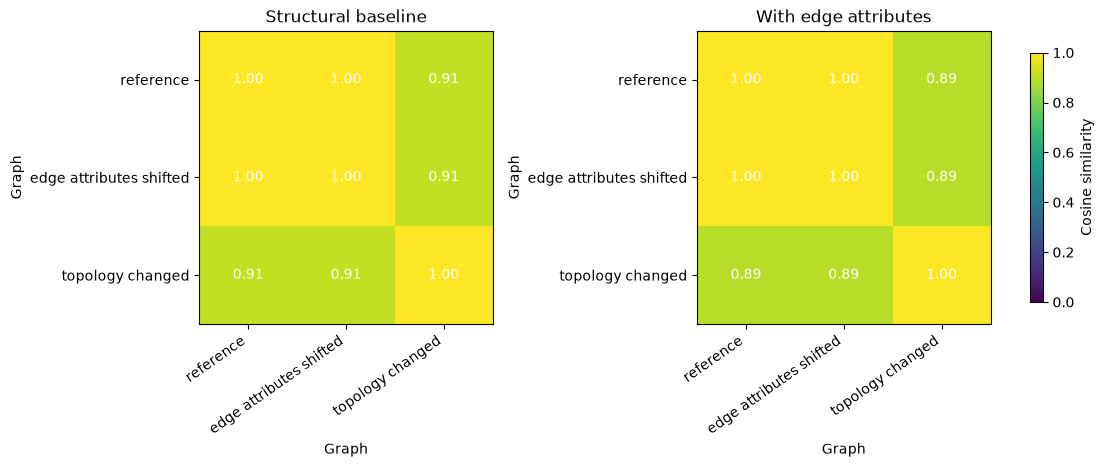

baseline graph-vector width: 64
edge-aware graph-vector width: 192


In [7]:
structural_encoder = NSPPK(
    radius=RADIUS, distance=DISTANCE, nbits=NBITS, dense=False, parallel=False
)
edge_aware_encoder = NSPPK(
    radius=RADIUS,
    distance=DISTANCE,
    nbits=NBITS,
    edge_attribute_key='edge_feature',
    dense=False,
    parallel=False,
)
X_structural = structural_encoder.fit_transform(graphs)
X_edge_aware = edge_aware_encoder.fit_transform(graphs)
K_structural = cosine_similarity(X_structural)
K_edge_aware = cosine_similarity(X_edge_aware)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, matrix, title in zip(
    axes,
    [K_structural, K_edge_aware],
    ['Structural baseline', 'With edge attributes'],
):
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis')
    ax.set_title(title)
    ax.set_xticks(range(len(graph_names)), graph_names, rotation=35, ha='right')
    ax.set_yticks(range(len(graph_names)), graph_names)
    ax.set_xlabel('Graph')
    ax.set_ylabel('Graph')
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            ax.text(column, row, f'{matrix[row, column]:.2f}', ha='center', va='center', color='white')
fig.colorbar(image, ax=axes, label='Cosine similarity', shrink=0.85)
plt.show()
print('baseline graph-vector width:', X_structural.shape[1])
print('edge-aware graph-vector width:', X_edge_aware.shape[1])

## Combine node and edge attributes

Node and edge attribute pipelines have independent settings because their vectors can have different widths. If both are enabled, graph-level NSPPK concatenates the node attribute weighted block and the edge attribute weighted block. Edge preprocessing can also be enabled independently.

In [8]:
combined_encoder = NSPPK(
    radius=RADIUS,
    distance=DISTANCE,
    nbits=NBITS,
    node_attribute_key='node_feature',
    edge_attribute_key='edge_feature',
    dense=False,
    parallel=False,
)
X_combined = combined_encoder.fit_transform(graphs)
node_width = len(graph.nodes[0]['node_feature']) * FEATURE_WIDTH
edge_width = len(graph.edges[edge_order[0]]['edge_feature']) * FEATURE_WIDTH
print('node block width:', node_width)
print('edge block width:', edge_width)
print('combined shape:', X_combined.shape)


node block width: 128
edge block width: 128
combined shape: (3, 256)


## Takeaways

- `EdgeNSPPK` provides one matrix row per edge, aligned to `graph.edges()`.
- An edge’s structural row sums the NSPPK feature rows of its two endpoints.
- Continuous edge attributes weight those edge rows to form a graph-level edge block.
- Optional edge clustering injects predicted edge categories into the existing structural hashes.
- When node and edge attributes are both active, their graph-level blocks are concatenated.